In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  
warnings.simplefilter(action='ignore', category=UserWarning)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report




In [2]:
df = pd.read_csv(r"C:\Users\carnival\Downloads\Life Expectancy Data.csv")

print(df.head())

       Country  Year      Status  Life expectancy  Adult Mortality  \
0  Afghanistan  2015  Developing             65.0            263.0   
1  Afghanistan  2014  Developing             59.9            271.0   
2  Afghanistan  2013  Developing             59.9            268.0   
3  Afghanistan  2012  Developing             59.5            272.0   
4  Afghanistan  2011  Developing             59.2            275.0   

   infant deaths  Alcohol  percentage expenditure  Hepatitis B  Measles  ...  \
0             62     0.01               71.279624         65.0     1154  ...   
1             64     0.01               73.523582         62.0      492  ...   
2             66     0.01               73.219243         64.0      430  ...   
3             69     0.01               78.184215         67.0     2787  ...   
4             71     0.01                7.097109         68.0     3013  ...   

   Polio  Total expenditure  Diphtheria  HIV/AIDS         GDP  Population  \
0    6.0             

In [3]:
print(df.shape)

print(df.dtypes)

print(df.info())


(12000, 22)
Country                             object
Year                                 int64
Status                              object
Life expectancy                    float64
Adult Mortality                    float64
infant deaths                        int64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
Measles                              int64
BMI                                float64
under-five deaths                    int64
Polio                              float64
Total expenditure                  float64
Diphtheria                         float64
HIV/AIDS                           float64
GDP                                float64
Population                         float64
thinness  1-19 years               float64
thinness 5-9 years                 float64
Income composition of resources    float64
Schooling                          float64
dtype: object
<class 'pandas.core.frame.Da

In [4]:
print(df.isnull().sum())


Country                               0
Year                                  0
Status                                0
Life expectancy                      10
Adult Mortality                      10
infant deaths                         0
Alcohol                             643
percentage expenditure                0
Hepatitis B                         993
Measles                               0
BMI                                 473
under-five deaths                     0
Polio                                19
Total expenditure                   226
Diphtheria                           19
HIV/AIDS                              0
GDP                                 905
Population                         1096
thinness  1-19 years                 34
thinness 5-9 years                   34
Income composition of resources     167
Schooling                           595
dtype: int64


In [5]:
print("Positive infinity count:", (df == np.inf).sum().sum())
print("Negative infinity count:", (df == -np.inf).sum().sum())

Positive infinity count: 0
Negative infinity count: 0


In [8]:
df_cleaned = df.copy()
for col in df_cleaned.columns:
    if df_cleaned[col].isnull().sum() > 0:
        if df_cleaned[col].dtype in ['float64', 'int64']:
            if abs(df_cleaned[col].skew()) > 1:
                df_cleaned[col].fillna(df_cleaned[col].median(), inplace=True)
            else:
                df_cleaned[col].fillna(df_cleaned[col].mean(), inplace=True)
        else:
            df_cleaned[col].fillna(df_cleaned[col].mode()[0], inplace=True)



print(df.isnull().sum())


Country                               0
Year                                  0
Status                                0
Life expectancy                      10
Adult Mortality                      10
infant deaths                         0
Alcohol                             643
percentage expenditure                0
Hepatitis B                         993
Measles                               0
BMI                                 473
under-five deaths                     0
Polio                                19
Total expenditure                   226
Diphtheria                           19
HIV/AIDS                              0
GDP                                 905
Population                         1096
thinness  1-19 years                 34
thinness 5-9 years                   34
Income composition of resources     167
Schooling                           595
dtype: int64


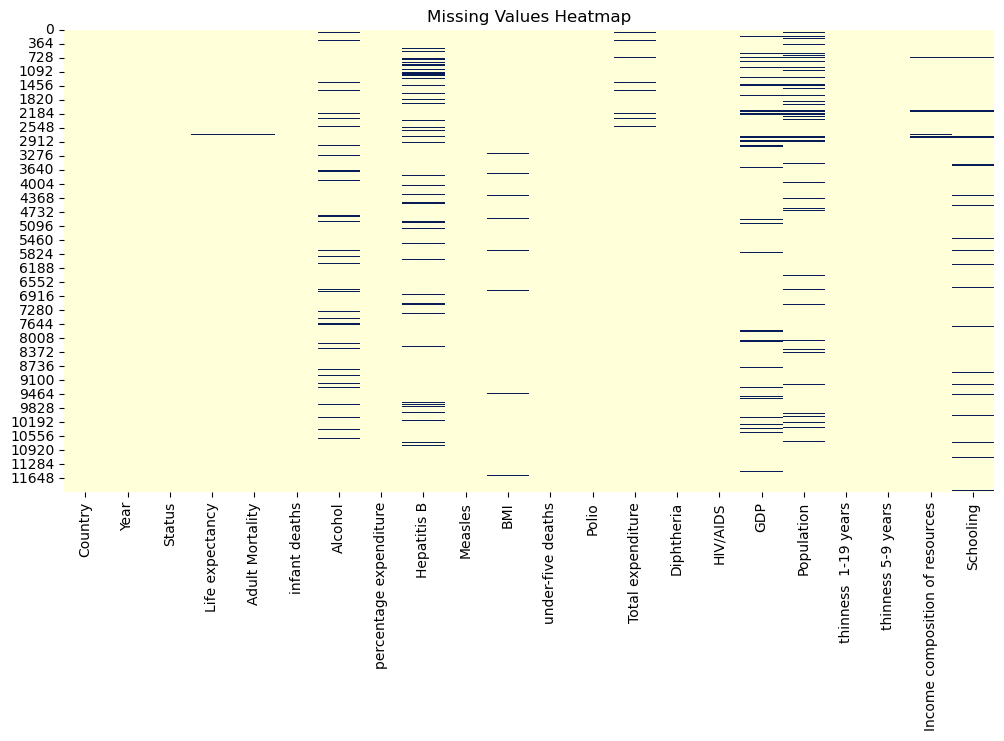

In [9]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False, cmap="YlGnBu")
plt.title("Missing Values Heatmap")
plt.show()


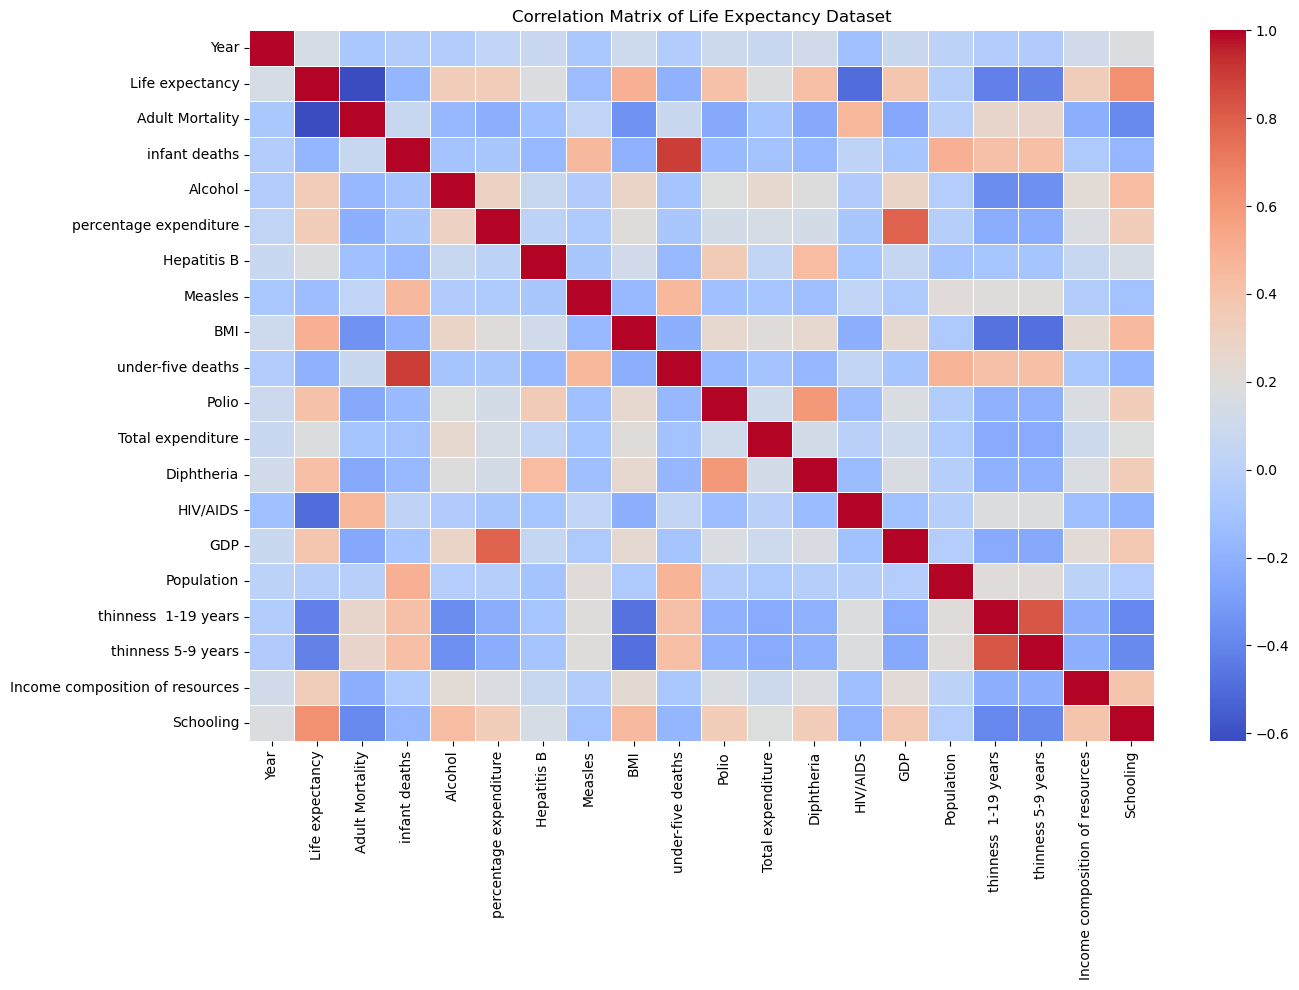

Top positively correlated features:
 Schooling     0.627352
BMI           0.498329
Diphtheria    0.421946
Polio         0.409833
GDP           0.382296
Name: Life expectancy, dtype: float64

Top negatively correlated features:
 under-five deaths      -0.197427
thinness 5-9 years     -0.410907
thinness  1-19 years   -0.417008
HIV/AIDS               -0.495743
Adult Mortality        -0.617654
Name: Life expectancy, dtype: float64


In [28]:
corr_matrix = df_cleaned.corr(numeric_only=True)

# Plot the heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Life Expectancy Dataset')
plt.tight_layout()
plt.show()

# Print top features most correlated with Life Expectancy
target_corr = corr_matrix['Life expectancy'].sort_values(ascending=False)
print("Top positively correlated features:\n", target_corr[1:6])
print("\nTop negatively correlated features:\n", target_corr[-5:])

<Axes: xlabel='GDP', ylabel='Life expectancy'>

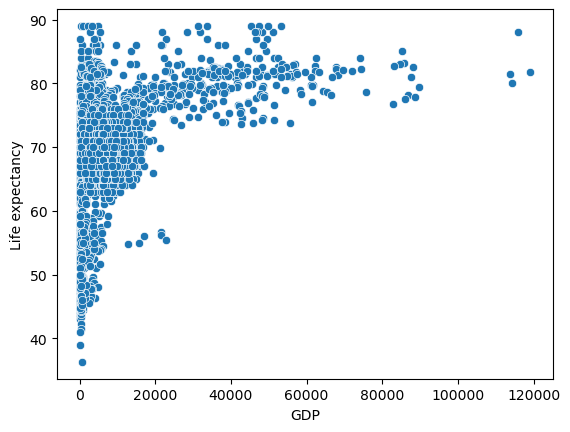

In [10]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)


sns.scatterplot(x='GDP', y='Life expectancy', data=df)

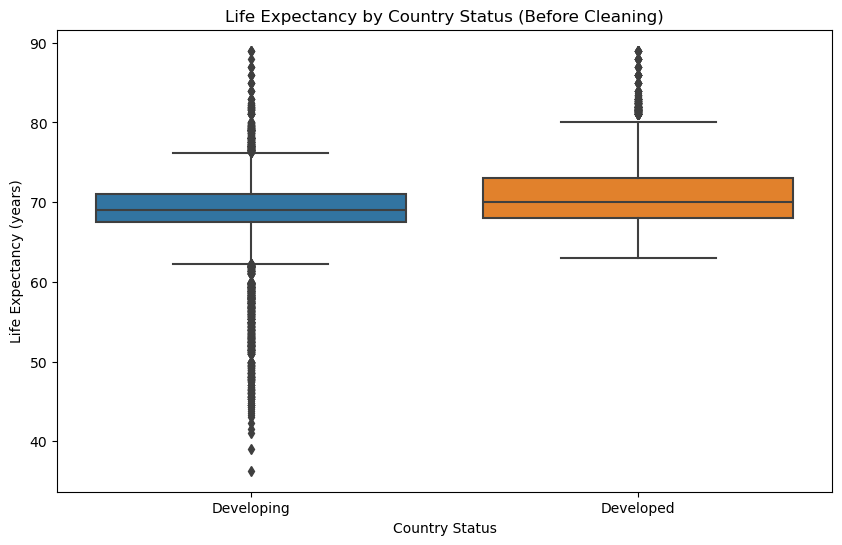

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Status', y='Life expectancy', data=df)
plt.title('Life Expectancy by Country Status (Before Cleaning)')
plt.xlabel('Country Status')
plt.ylabel('Life Expectancy (years)')
plt.show()

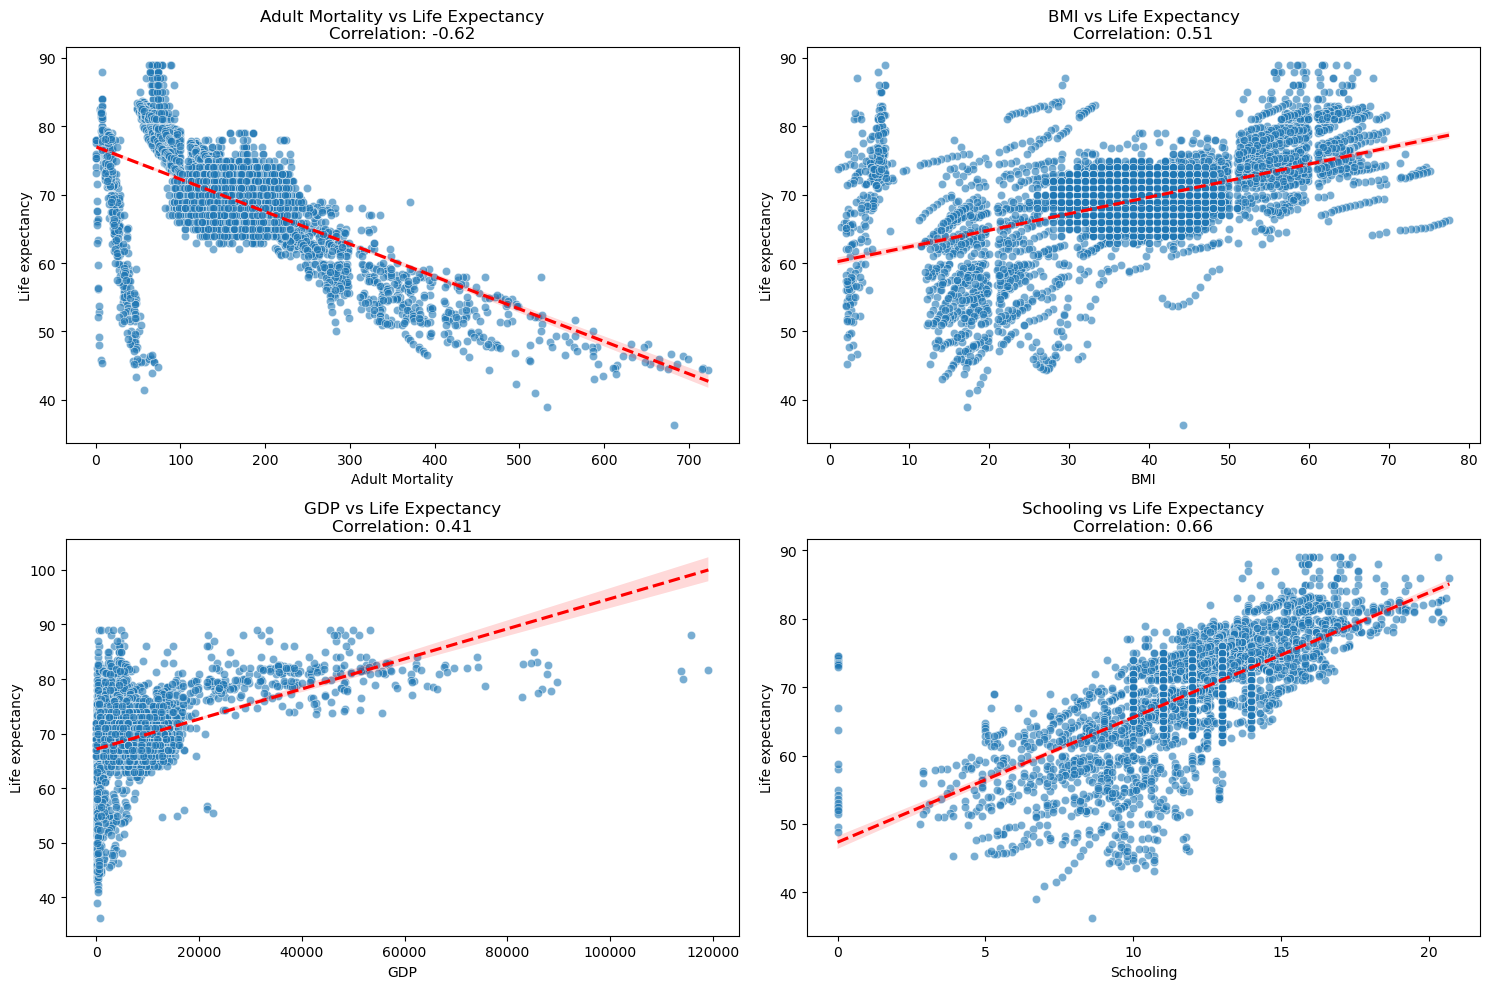

In [14]:
important_cols = ['Adult Mortality', 'BMI', 'GDP', 'Schooling']
plt.figure(figsize=(15,10))

for i, col in enumerate(important_cols, 1):
    plt.subplot(2,2,i)
    sns.scatterplot(x=col, y='Life expectancy', data=df, alpha=0.6)
    
    corr = df[[col, 'Life expectancy']].corr().iloc[0,1]
    plt.title(f'{col} vs Life Expectancy\nCorrelation: {corr:.2f}')
    
    # Add regression line
    sns.regplot(x=col, y='Life expectancy', data=df, 
                scatter=False, color='red', line_kws={'linestyle':'--'})
    
plt.tight_layout()
plt.show()

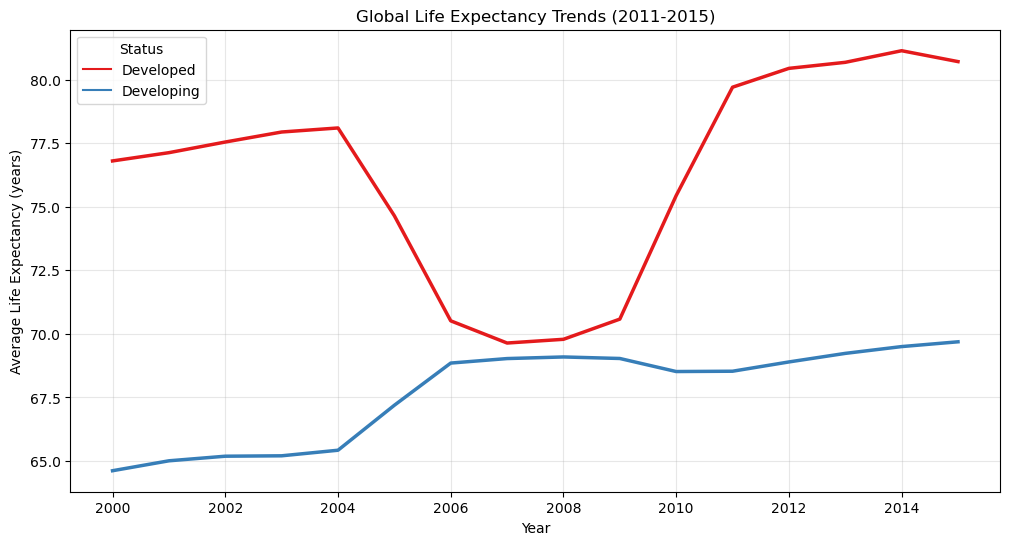

In [15]:
plt.figure(figsize=(12,6))
sns.lineplot(x='Year', y='Life expectancy', hue='Status', 
             data=df.groupby(['Year','Status'])['Life expectancy'].mean().reset_index(),
             palette='Set1', linewidth=2.5)
plt.title('Global Life Expectancy Trends (2011-2015)')
plt.ylabel('Average Life Expectancy (years)')
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
# Encode categorical variables
df_encoded = df_cleaned.copy()
le = LabelEncoder()
df_encoded['Status'] = le.fit_transform(df_encoded['Status'])  # 0: Developed, 1: Developing

# Convert Life Expectancy to categories
def categorize_life_expectancy(val):
    if val < 60:
        return 'Low'
    elif val <= 70:
        return 'Medium'
    else:
        return 'High'

df_encoded['Life_expectancy_class'] = df_encoded['Life expectancy'].apply(categorize_life_expectancy)


In [21]:
X = df_encoded.drop(columns=['Country', 'Year', 'Life expectancy', 'Life_expectancy_class'])
y = df_encoded['Life_expectancy_class']



In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [23]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [29]:
pca_components_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=X.columns
).sort_values(by='PC1', ascending=False)

# Print the top contributing features for PC1 and PC2
print("Top contributing features to PC1 and PC2:")
print(pca_components_df.head(10))

Top contributing features to PC1 and PC2:
                           PC1       PC2
thinness 5-9 years    0.336044  0.093384
thinness  1-19 years  0.335759  0.091127
under-five deaths     0.257507  0.453417
infant deaths         0.253881  0.461614
Adult Mortality       0.222150 -0.209923
Measles               0.160420  0.305655
Status                0.144487 -0.137108
HIV/AIDS              0.138539 -0.149513
Population            0.129914  0.379376
Hepatitis B          -0.137174 -0.023391


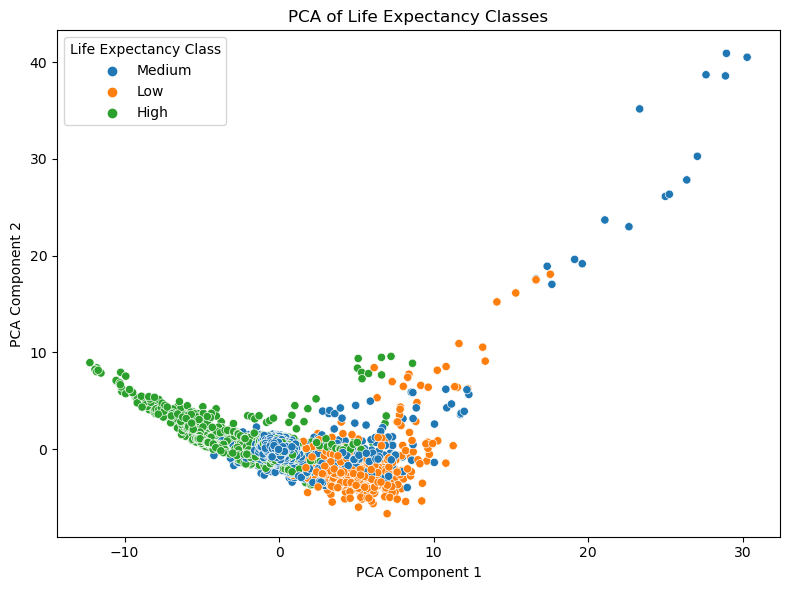

In [24]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y)
plt.title('PCA of Life Expectancy Classes')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Life Expectancy Class')
plt.tight_layout()
plt.show()

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)


In [26]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_model.fit(X_train, y_train)

SVC()

In [27]:
# Predict
y_pred = svm_model.predict(X_test)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[ 299    0  473]
 [   0  109    9]
 [  20    9 1481]]

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.39      0.55       772
         Low       0.92      0.92      0.92       118
      Medium       0.75      0.98      0.85      1510

    accuracy                           0.79      2400
   macro avg       0.87      0.76      0.77      2400
weighted avg       0.82      0.79      0.76      2400

